In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/retail_customer_churn_100k (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (100000, 18)


,customer_id,age_group,gender,region,customer_segment,preferred_channel,purchase_frequency,avg_order_value,total_spent,recency_days,website_visits,discount_usage_rate,email_open_rate,cart_abandonment_rate,loyalty_score,engagement_score,churn_risk,churn_flag
0,C000001,18-24,Other,North,Loyal,Online,5,381.27,2108.80,189,27,0.38,0.13,0.42,33,35.5,Medium,1
1,C000002,25-34,Other,South,New,Mobile App,12,376.65,3843.06,277,68,0.51,0.06,0.07,68,49.5,Medium,1
2,C000003,55+,Other,North,VIP,Online,5,37.73,224.65,271,23,0.64,0.22,0.46,73,38.0,High,1
3,C000004,18-24,Male,North,Returning,Mobile App,12,191.19,1960.79,89,93,0.66,0.31,0.13,93,59.0,Low,0
4,C000005,55+,Other,North,Returning,Mobile App,2,279.64,594.79,264,4,0.73,0.27,0.58,11,34.5,High,1


In [5]:
print(df["churn_flag"].value_counts())

print("\nPercentage:")
print(
    df["churn_flag"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn_flag
0    53776
1    46224
Name: count, dtype: int64

Percentage:
churn_flag
0    53.78
1    46.22
Name: proportion, dtype: float64


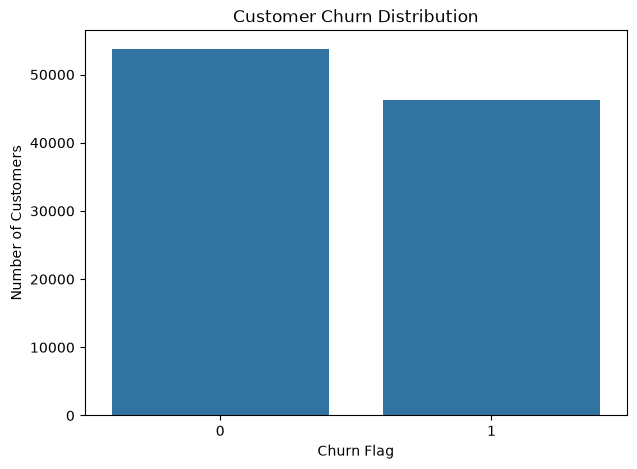

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="churn_flag"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Flag")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
risk_churn = pd.crosstab(
    df["churn_risk"],
    df["churn_flag"],
    normalize="index"
) * 100

risk_churn.round(2)

churn_flag,0,1
churn_risk,,
High,0.00,100.00
Low,100.00,0.00
Medium,49.67,50.33


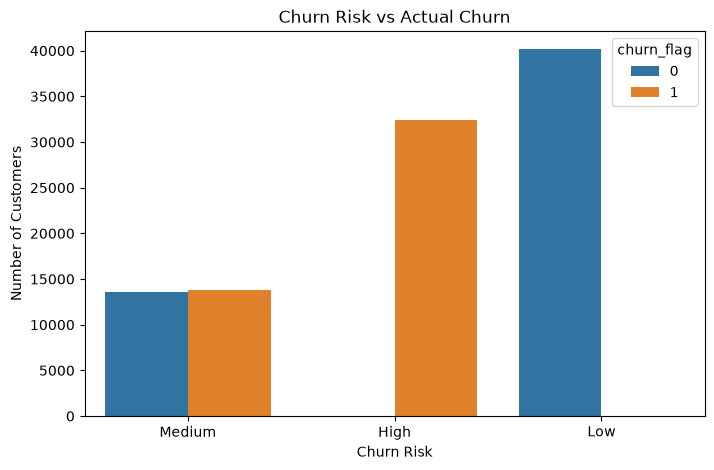

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="churn_risk",
    hue="churn_flag"
)

plt.title("Churn Risk vs Actual Churn")
plt.xlabel("Churn Risk")
plt.ylabel("Number of Customers")

plt.show()

In [9]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print(numerical_columns)

['purchase_frequency', 'avg_order_value', 'total_spent', 'recency_days', 'website_visits', 'discount_usage_rate', 'email_open_rate', 'cart_abandonment_rate', 'loyalty_score', 'engagement_score', 'churn_flag']


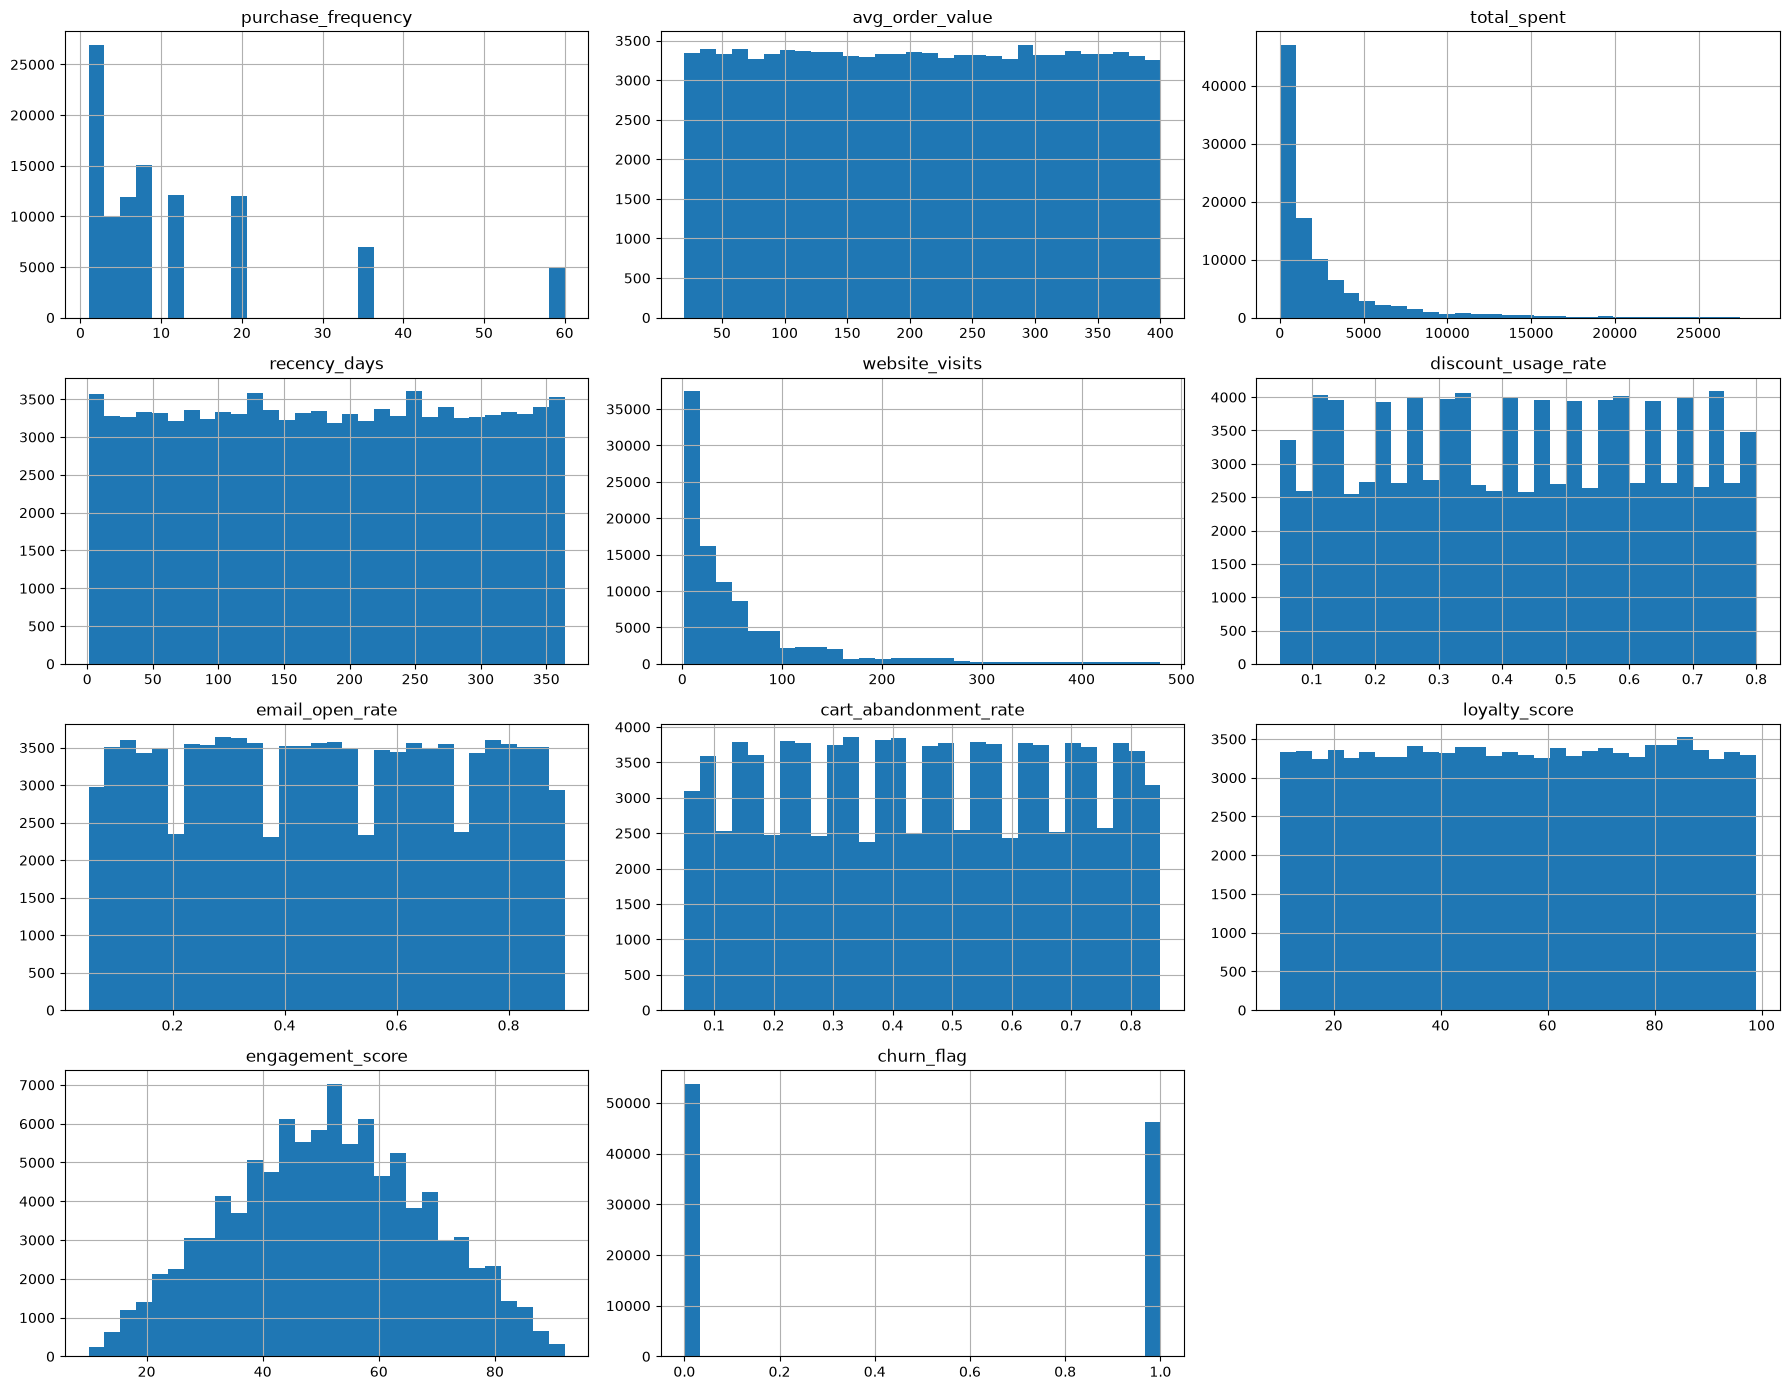

In [10]:
df[numerical_columns].hist(
    figsize=(18, 14),
    bins=30
)

plt.tight_layout()
plt.show()

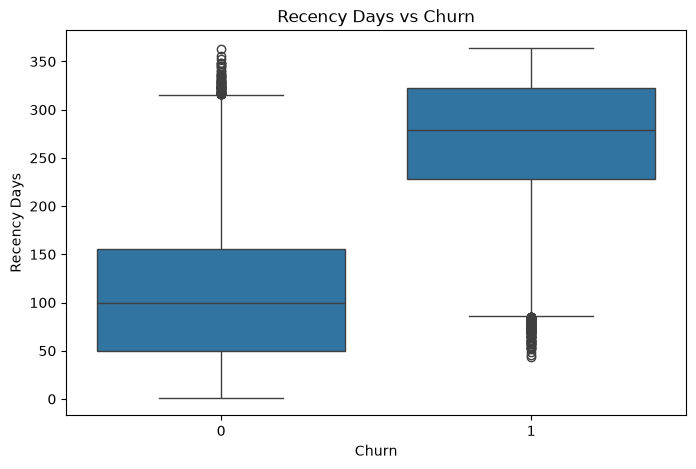

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="recency_days"
)

plt.title("Recency Days vs Churn")
plt.xlabel("Churn")
plt.ylabel("Recency Days")

plt.show()

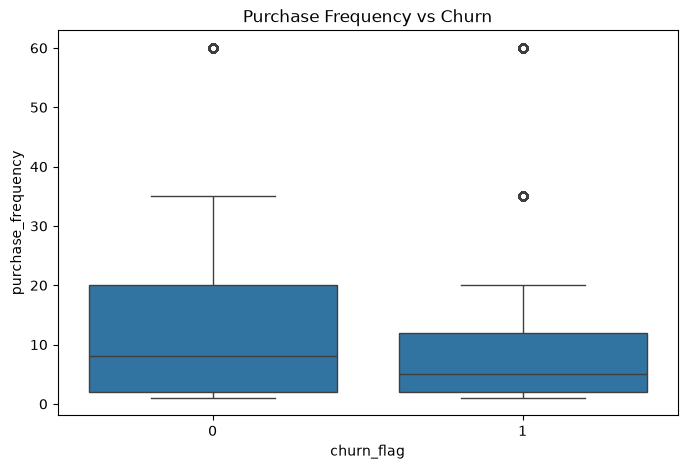

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="purchase_frequency"
)

plt.title("Purchase Frequency vs Churn")
plt.show()

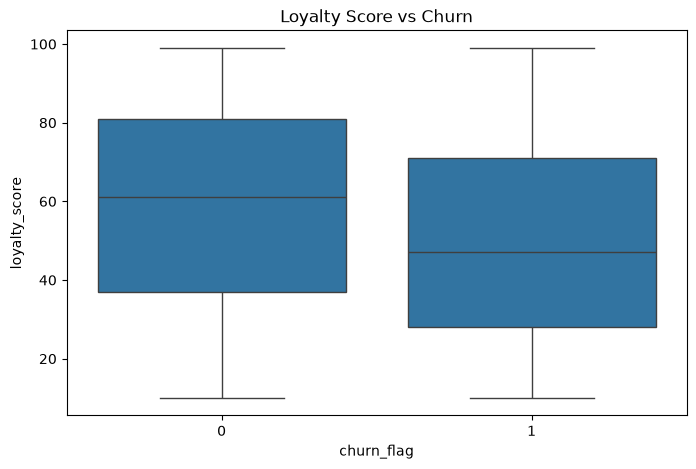

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="loyalty_score"
)

plt.title("Loyalty Score vs Churn")
plt.show()

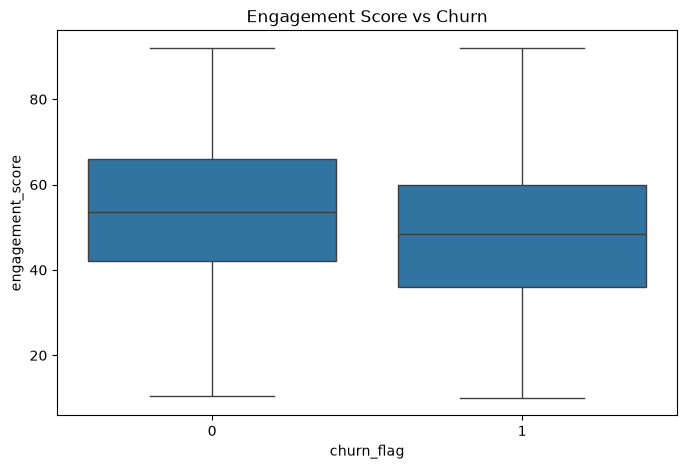

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="engagement_score"
)

plt.title("Engagement Score vs Churn")
plt.show()

In [15]:
segment_churn = pd.crosstab(
    df["customer_segment"],
    df["churn_flag"],
    normalize="index"
) * 100

segment_churn.round(2)

churn_flag,0,1
customer_segment,,
Loyal,54.07,45.93
New,53.68,46.32
Returning,54.02,45.98
VIP,53.33,46.67


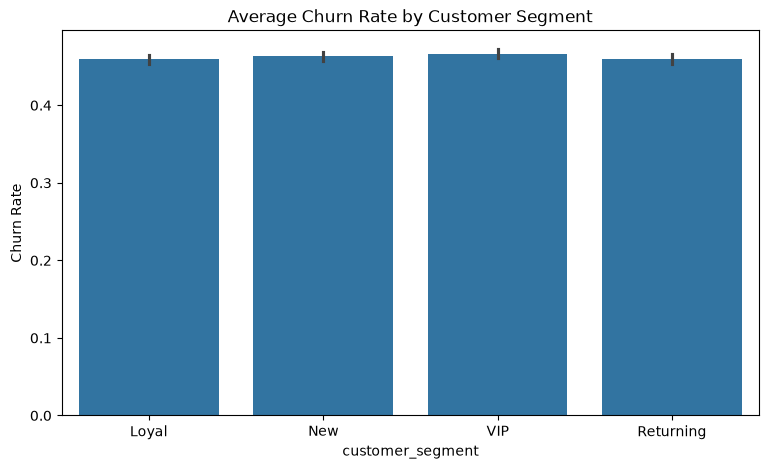

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="customer_segment",
    y="churn_flag"
)

plt.title("Average Churn Rate by Customer Segment")
plt.ylabel("Churn Rate")

plt.show()

In [17]:
channel_churn = pd.crosstab(
    df["preferred_channel"],
    df["churn_flag"],
    normalize="index"
) * 100

channel_churn.round(2)

churn_flag,0,1
preferred_channel,,
In-Store,53.74,46.26
Mobile App,54.25,45.75
Online,53.34,46.66


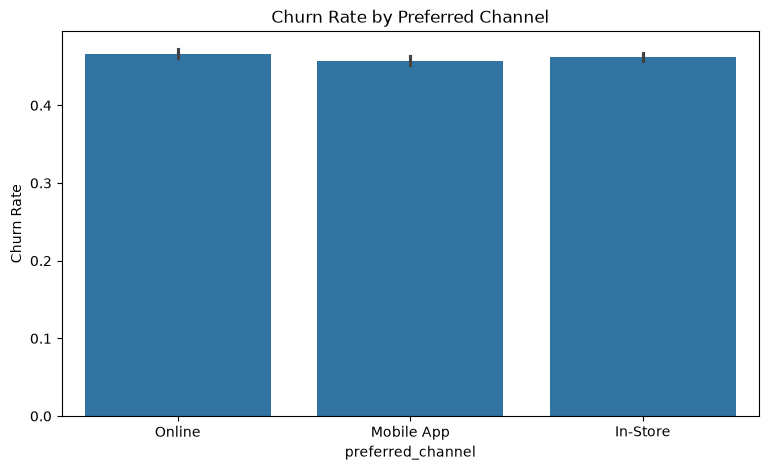

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="preferred_channel",
    y="churn_flag"
)

plt.title("Churn Rate by Preferred Channel")
plt.ylabel("Churn Rate")

plt.show()

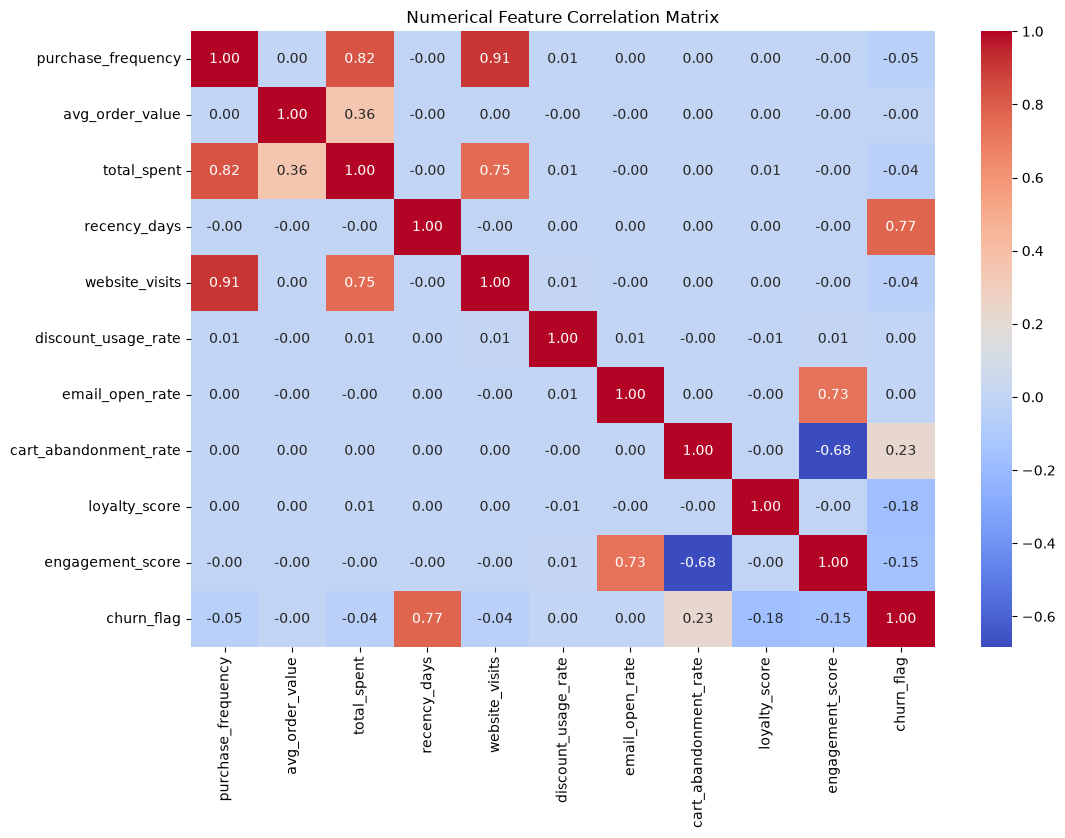

In [19]:
correlation = df[numerical_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Numerical Feature Correlation Matrix")

plt.show()

In [20]:
churn_comparison = df.groupby(
    "churn_flag"
)[numerical_columns].mean().T

churn_comparison

churn_flag,0,1
purchase_frequency,12.466342,11.029595
avg_order_value,210.145141,209.192351
total_spent,2692.556727,2370.936140
recency_days,107.301993,270.504110
website_visits,61.745649,54.776804
discount_usage_rate,0.425870,0.426681
email_open_rate,0.473958,0.475171
cart_abandonment_rate,0.402234,0.507693
loyalty_score,58.834926,49.709588
engagement_score,53.586209,48.373875
